# Assignment 3 - Model Optimization Pipeline (Quantization + Pruning)
Edge Computing & Intelligent Systems - ResNet-18 on CIFAR-10.

Every step is a standalone script; this notebook runs them in order and shows their output. Run all cells top to bottom.
Training stages are skipped when their checkpoint already exists; set `RETRAIN = True` to retrain everything (about 30 minutes on a GPU).

On Windows, Jupyter shows the output of each step only when that step finishes, so a long step can look idle while it runs.

In [1]:
import sys
from pathlib import Path
import torch

RETRAIN = False   # True: retrain every stage

def run(script, *args, ckpt=None):
    """Run a script and stream its output; skip a training stage if its checkpoint exists."""
    if ckpt and Path(ckpt).exists() and not RETRAIN:
        print(f"{ckpt} exists - skipped (set RETRAIN = True to retrain)")
    else:
        get_ipython().system(f"{sys.executable} -u {script} {' '.join(args)}")

print("python :", sys.version.split()[0])
print("torch  :", torch.__version__, "| CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("quant engines:", torch.backends.quantized.supported_engines)

python : 3.11.14
torch  : 2.10.0+cu130 | CUDA: True | NVIDIA GeForce RTX 4060 Laptop GPU
quant engines: ['onednn']


In [14]:
# Is the dataset available? (the scripts download CIFAR-10 on first use if it is missing)
if Path("data/cifar-10-batches-py").exists():
    print("CIFAR-10 found in data/ - nothing to download.")
else:
    print("CIFAR-10 not found in data/ - it will be downloaded automatically (about 170 MB) by the first cell that needs it.")
    print("That cell can look idle for a minute or two; Jupyter on Windows shows a script's output only when it finishes.")

CIFAR-10 found in data/ - nothing to download.


## Q1.1 - FP32 baseline (ResNet-18 trained from scratch)

In [2]:
run("train_baseline.py", ckpt="checkpoints/fp32.pth")

[fp32] epoch  1/40  loss 1.838  val_acc 46.68%  (12s)
[fp32] epoch  2/40  loss 1.485  val_acc 59.50%  (11s)
[fp32] epoch  3/40  loss 1.301  val_acc 66.08%  (11s)
[fp32] epoch  4/40  loss 1.179  val_acc 72.40%  (11s)
[fp32] epoch  5/40  loss 1.089  val_acc 75.74%  (11s)
[fp32] epoch  6/40  loss 1.011  val_acc 76.98%  (11s)
[fp32] epoch  7/40  loss 0.962  val_acc 77.20%  (11s)
[fp32] epoch  8/40  loss 0.911  val_acc 77.60%  (11s)
[fp32] epoch  9/40  loss 0.875  val_acc 80.26%  (11s)
[fp32] epoch 10/40  loss 0.845  val_acc 74.96%  (11s)
[fp32] epoch 11/40  loss 0.813  val_acc 84.72%  (11s)
[fp32] epoch 12/40  loss 0.794  val_acc 86.34%  (11s)
[fp32] epoch 13/40  loss 0.773  val_acc 86.50%  (11s)
[fp32] epoch 14/40  loss 0.755  val_acc 84.98%  (11s)
[fp32] epoch 15/40  loss 0.739  val_acc 83.46%  (10s)
[fp32] epoch 16/40  loss 0.730  val_acc 86.22%  (11s)
[fp32] epoch 17/40  loss 0.717  val_acc 85.80%  (11s)
[fp32] epoch 18/40  loss 0.703  val_acc 85.70%  (11s)
[fp32] epoch 19/40  loss 0.6

## Q1.2 - Post-Training Static Quantization (fuse, backend, calibrate, convert)

In [3]:
run("ptq.py")

FP32 accuracy: 93.69%
PTQ INT8 accuracy: 93.70%
saved checkpoints/ptq_int8.pt


## Q1.3 - Quantization-Aware Training (fake-quant fine-tune, convert to INT8)

In [4]:
run("qat.py", ckpt="checkpoints/qat_int8.pt")

[qat] epoch  1/8  loss 0.078  val_acc 94.38%  (64s)
[qat] epoch  2/8  loss 0.042  val_acc 94.44%  (65s)
[qat] epoch  3/8  loss 0.028  val_acc 94.20%  (64s)
[qat] epoch  4/8  loss 0.022  val_acc 94.22%  (64s)
[qat] epoch  5/8  loss 0.019  val_acc 94.26%  (63s)
[qat] epoch  6/8  loss 0.016  val_acc 94.32%  (63s)
[qat] epoch  7/8  loss 0.010  val_acc 94.06%  (37s)
[qat] epoch  8/8  loss 0.007  val_acc 94.36%  (38s)

QAT INT8 accuracy: 93.69%
saved checkpoints/qat_int8.pt


## Q2.2 - Iterative unstructured magnitude pruning (masking, fine-tuning, permanent removal)

In [5]:
run("prune_unstructured.py", ckpt="checkpoints/pruned_unstructured.pth")

[prune 1/5 @ 40%] epoch  1/6  loss 0.058  val_acc 93.46%  (11s)
[prune 1/5 @ 40%] epoch  2/6  loss 0.034  val_acc 92.38%  (11s)
[prune 1/5 @ 40%] epoch  3/6  loss 0.039  val_acc 92.96%  (11s)
[prune 1/5 @ 40%] epoch  4/6  loss 0.036  val_acc 92.98%  (11s)
[prune 1/5 @ 40%] epoch  5/6  loss 0.022  val_acc 94.06%  (11s)
[prune 1/5 @ 40%] epoch  6/6  loss 0.013  val_acc 94.10%  (11s)
[prune 2/5 @ 60%] epoch  1/6  loss 0.017  val_acc 93.18%  (11s)
[prune 2/5 @ 60%] epoch  2/6  loss 0.032  val_acc 92.84%  (11s)
[prune 2/5 @ 60%] epoch  3/6  loss 0.037  val_acc 91.36%  (11s)
[prune 2/5 @ 60%] epoch  4/6  loss 0.026  val_acc 93.58%  (11s)
[prune 2/5 @ 60%] epoch  5/6  loss 0.017  val_acc 93.88%  (11s)
[prune 2/5 @ 60%] epoch  6/6  loss 0.011  val_acc 93.94%  (11s)
[prune 3/5 @ 75%] epoch  1/6  loss 0.021  val_acc 93.08%  (11s)
[prune 3/5 @ 75%] epoch  2/6  loss 0.028  val_acc 92.32%  (11s)
[prune 3/5 @ 75%] epoch  3/6  loss 0.028  val_acc 92.72%  (11s)
[prune 3/5 @ 75%] epoch  4/6  loss 0.025

## Q2.3 - Structured channel pruning (rebuilt architecture) and fine-tuning

In [6]:
run("prune_structured.py", ckpt="checkpoints/pruned_structured.pth")

inner widths per block: [32, 32, 64, 64, 128, 128, 256, 256]
params 11.17M -> 5.68M (49% fewer), MACs 555M -> 282M (49% fewer)
validation accuracy right after pruning (no fine-tune): 39.30%
[structured] epoch  1/30  loss 0.599  val_acc 91.54%  (7s)
[structured] epoch  2/30  loss 0.578  val_acc 91.00%  (7s)
[structured] epoch  3/30  loss 0.613  val_acc 87.30%  (7s)
[structured] epoch  4/30  loss 0.639  val_acc 86.88%  (7s)
[structured] epoch  5/30  loss 0.648  val_acc 88.46%  (7s)
[structured] epoch  6/30  loss 0.648  val_acc 88.14%  (7s)
[structured] epoch  7/30  loss 0.644  val_acc 87.78%  (7s)
[structured] epoch  8/30  loss 0.634  val_acc 87.08%  (7s)
[structured] epoch  9/30  loss 0.628  val_acc 88.78%  (7s)
[structured] epoch 10/30  loss 0.625  val_acc 84.84%  (7s)
[structured] epoch 11/30  loss 0.614  val_acc 87.10%  (7s)
[structured] epoch 12/30  loss 0.612  val_acc 89.84%  (7s)
[structured] epoch 13/30  loss 0.606  val_acc 89.28%  (7s)
[structured] epoch 14/30  loss 0.596  val_a

## Inference pipeline - all five models

In [7]:
for m in ["fp32", "ptq_int8", "qat_int8", "unstructured", "structured"]:
    run("inference.py", "--model", m, "--n", "5")
    print()

model: fp32 on cpu
     test[0]: cat        (90.7%)  true=cat        OK
     test[1]: ship       (91.7%)  true=ship       OK
     test[2]: ship       (84.3%)  true=ship       OK
     test[3]: airplane   (93.3%)  true=airplane   OK
     test[4]: frog       (91.6%)  true=frog       OK



model: ptq_int8 on cpu
     test[0]: cat        (90.7%)  true=cat        OK
     test[1]: ship       (91.7%)  true=ship       OK
     test[2]: ship       (83.6%)  true=ship       OK
     test[3]: airplane   (93.3%)  true=airplane   OK
     test[4]: frog       (91.6%)  true=frog       OK



model: qat_int8 on cpu
     test[0]: cat        (99.7%)  true=cat        OK
     test[1]: ship       (99.7%)  true=ship       OK
     test[2]: ship       (96.2%)  true=ship       OK
     test[3]: airplane   (99.7%)  true=airplane   OK
     test[4]: frog       (99.7%)  true=frog       OK



model: unstructured on cpu
     test[0]: cat        (100.0%)  true=cat        OK
     test[1]: ship       (99.8%)  true=ship       OK
     test[2]: ship       (98.3%)  true=ship       OK
     test[3]: airplane   (99.9%)  true=airplane   OK
     test[4]: frog       (99.9%)  true=frog       OK



model: structured on cpu
     test[0]: cat        (90.4%)  true=cat        OK
     test[1]: ship       (89.9%)  true=ship       OK
     test[2]: automobile (80.8%)  true=ship       WRONG
     test[3]: airplane   (92.1%)  true=airplane   OK
     test[4]: frog       (91.0%)  true=frog       OK



## Benchmark - all five models on the CIFAR-10 test set

In [8]:
run("benchmark.py")

fp32          acc 93.69%  cpu 10.42 ms  317 img/s
ptq_int8      acc 93.70%  cpu 22.73 ms  1543 img/s
qat_int8      acc 93.69%  cpu 35.38 ms  421 img/s
unstructured  acc 93.53%  cpu 10.47 ms  151 img/s
structured    acc 93.91%  cpu 3.12 ms  269 img/s

(CPU threads for latency/throughput: 4)
       model  accuracy_pct  file_size_mb  gzip_size_mb  params_m  nonzero_params_m  macs_m  cpu_latency_ms_bs1  cpu_throughput_img_s_bs128  gpu_latency_ms_bs1
        fp32         93.69         42.69         39.60     11.17             11.17     555               10.42                         317                1.80
    ptq_int8         93.70         10.89          9.69     11.17             11.17     555               22.73                        1543                 NaN
    qat_int8         93.69         10.89          9.69     11.17             11.17     555               35.38                         421                 NaN
unstructured         93.53         42.70          7.69     11.17         

In [9]:
import pandas as pd
bench = pd.read_csv("results/benchmark.csv")
bench.set_index("model").T   # one column per model

model,fp32,ptq_int8,qat_int8,unstructured,structured
accuracy_pct,93.69,93.70,93.69,93.53,93.91
file_size_mb,42.69,10.89,10.89,42.70,21.73
gzip_size_mb,39.60,9.69,9.69,7.69,20.13
params_m,11.17,11.17,11.17,11.17,5.68
nonzero_params_m,11.17,11.17,11.17,1.13,5.68
macs_m,555.00,555.00,555.00,555.00,282.00
cpu_latency_ms_bs1,10.42,22.73,35.38,10.47,3.12
cpu_throughput_img_s_bs128,317.00,1543.00,421.00,151.00,269.00
gpu_latency_ms_bs1,1.80,NaN,NaN,4.56,1.94


In [10]:
pd.read_csv("results/predictions.csv").head(10)

,index,label,fp32,ptq_int8,qat_int8,unstructured,structured
0,0,3,3,3,3,3,3
1,1,8,8,8,8,8,8
2,2,8,8,8,8,8,1
3,3,0,0,0,0,0,0
4,4,6,6,6,6,6,6
5,5,6,6,6,6,6,6
6,6,1,1,1,1,1,1
7,7,6,6,6,6,6,6
8,8,3,3,3,3,3,3
9,9,1,1,1,1,1,1


## ONNX deployment - export and ONNX Runtime CPU inference

In [11]:
run("export_onnx.py")

exported fp32.onnx
exported unstructured.onnx
exported structured.onnx
exported fp32_int8.onnx (ONNX Runtime static INT8)


In [12]:
run("onnx_inference.py")

fp32.onnx          acc 93.69%
fp32_int8.onnx     acc 93.79%
structured.onnx    acc 93.91%
unstructured.onnx  acc 93.53%

(ONNX Runtime CPU, 4 threads)
       onnx_model  accuracy_pct  file_size_mb  cpu_latency_ms_bs1  cpu_throughput_img_s_bs128
        fp32.onnx         93.69         42.62                2.77                         449
   fp32_int8.onnx         93.79         10.71                0.90                        1480
  structured.onnx         93.91         21.66                1.33                         872
unstructured.onnx         93.53         42.62                2.47                         465


## Figures

figures written to results/graphs


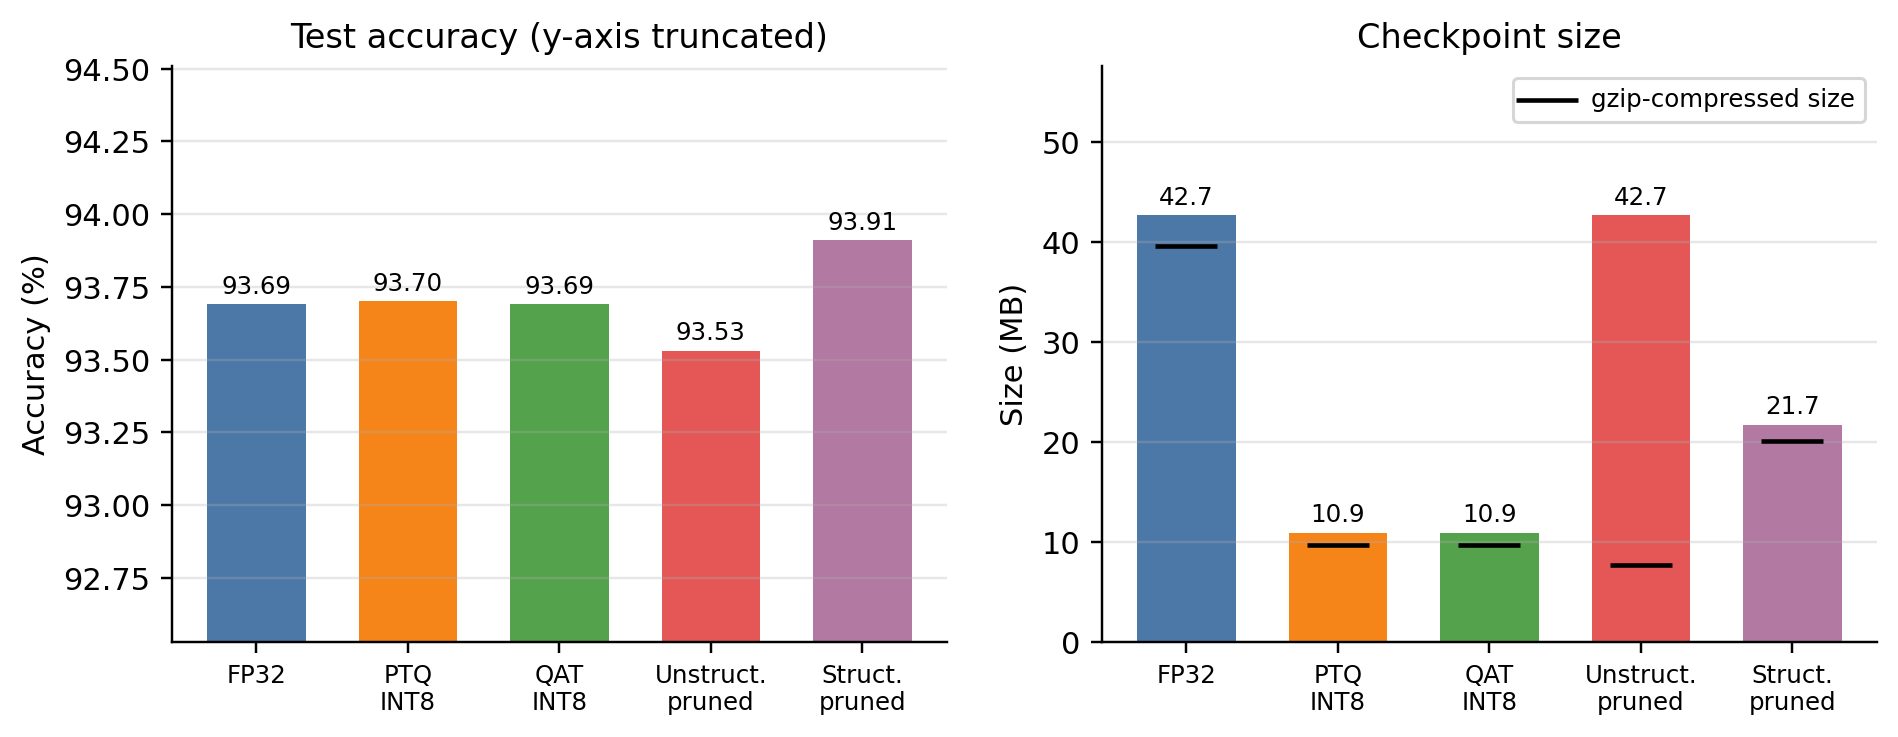

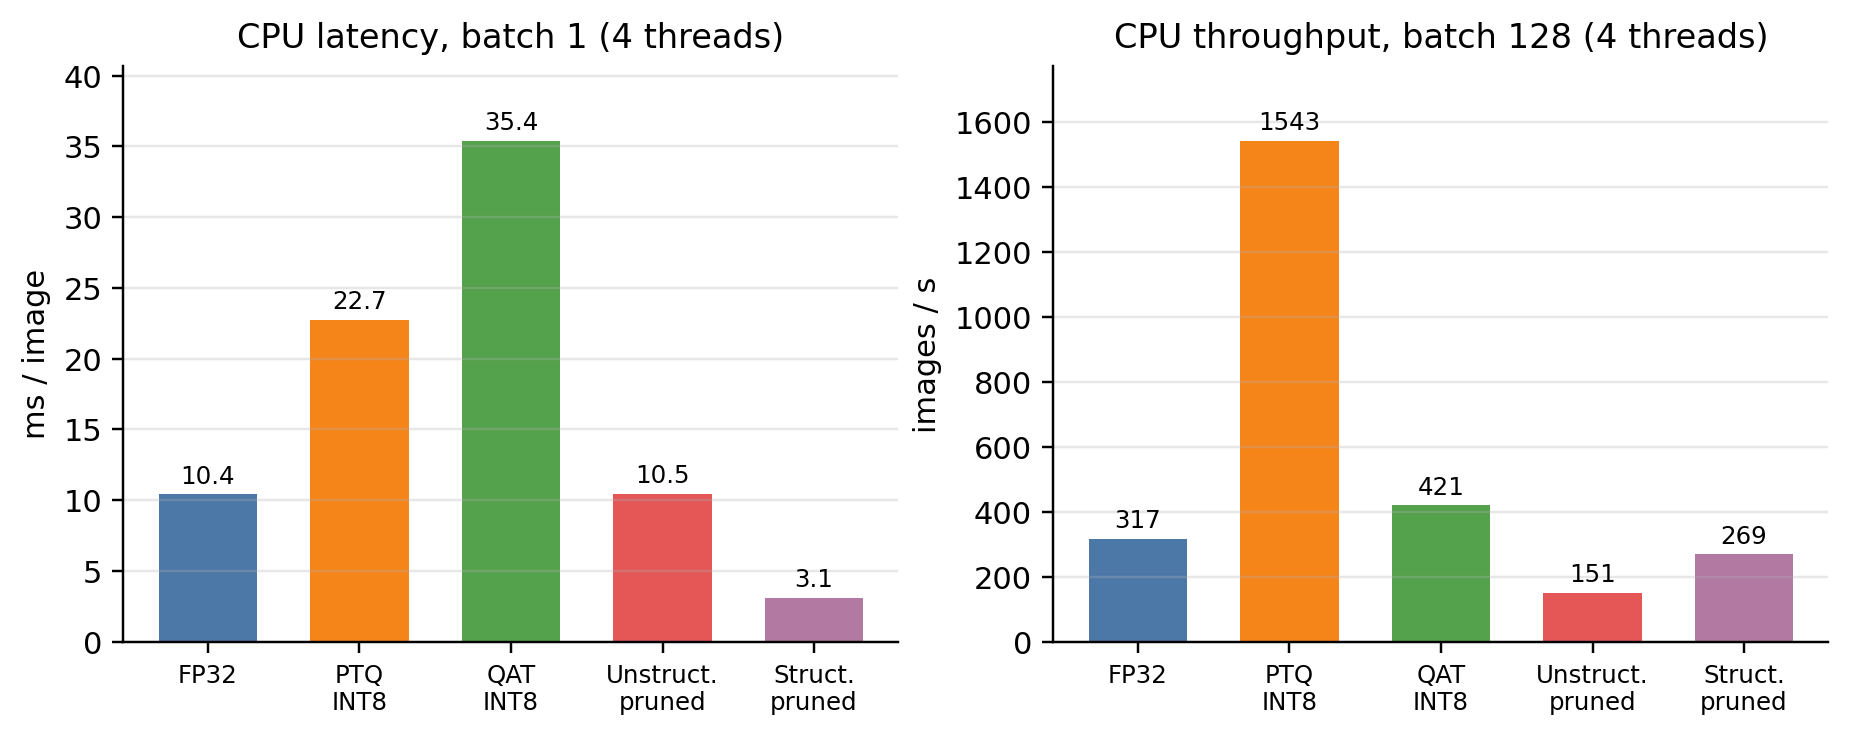

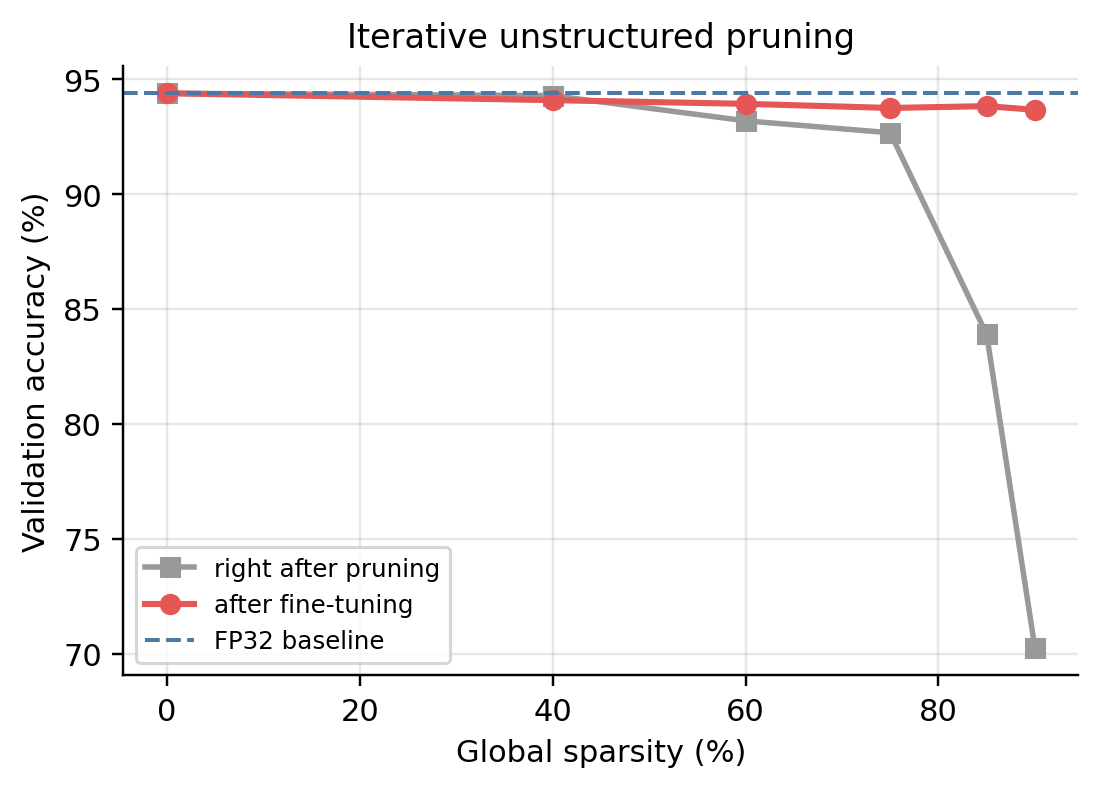

In [13]:
run("make_plots.py")
from IPython.display import Image, display
for f in ["fig_benchmark_accuracy_size", "fig_benchmark_speed", "fig_unstructured_pruning"]:
    display(Image(f"results/graphs/{f}.png", width=800))